# Step 6 — Version B on GPU: vLLM on a Kaggle T4

Part of **llm-serving-at-scale**. This notebook:
1. starts **vLLM** (continuous batching + PagedAttention) on **one** T4 GPU,
2. runs a **batch-size sweep** (1 → 256 concurrent requests) and compares it with llama.cpp on CPU,
3. runs the **same Locust load test** used for every other version (10 / 100 / 1000 users),
4. zips the results so you can copy them back into the repo.

**Before running — notebook settings (right sidebar):**
- **Accelerator: `GPU T4 x2`** (not P100: it's compute capability 6.0, below vLLM's 7.5 minimum). We use one of the two GPUs.
- **Internet: On** (needs a phone-verified Kaggle account).

Then **Run All**. Expect ~35–45 min of GPU time (install ~5, sweep ~3, load tests ~25).

In [1]:
# ---- configuration -------------------------------------------------------------
REPO_URL = "https://github.com/rohithram22/llm-serving-at-scale.git"
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
VLLM_VERSION = "0.18.1"      # known-good on Kaggle T4 (Sep 2026). If the install fails, set "" for latest.
GPU_MEM_UTIL = 0.85          # fraction of GPU memory vLLM may use (weights + KV cache + activations)
MAX_MODEL_LEN = 4096         # max tokens per request (prompt + answer)
MAX_NUM_SEQS = 256           # max requests decoded together = the continuous-batching batch limit
SWEEP_LEVELS = [1, 2, 4, 8, 16, 32, 64, 128, 256]
USERS_LIST = [10, 100, 1000]
LOAD_DURATION_S = 180
LABEL = "vllm_t4_fp16"
WORK = "/kaggle/working"
REPO_DIR = f"{WORK}/llm-serving-at-scale"
PORT = 8000

## 1. Check the GPU

In [2]:
import subprocess

def sh(cmd: str, check: bool = True) -> str:
    """Run a shell command, print and return its output."""
    p = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (p.stdout + p.stderr).strip()
    if out:
        print(out)
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}")
    return out

gpus = sh("nvidia-smi --query-gpu=index,name,memory.total,compute_cap --format=csv,noheader")
cap = float(gpus.splitlines()[0].split(",")[-1])
assert cap >= 7.5, (f"GPU compute capability {cap} < 7.5: vLLM won't run. "
                    "Switch the accelerator to 'GPU T4 x2' in the notebook settings.")
print(f"\nOK: compute capability {cap}. We'll use GPU 0 only (one replica).")

0, Tesla T4, 15360 MiB, 7.5
1, Tesla T4, 15360 MiB, 7.5

OK: compute capability 7.5. We'll use GPU 0 only (one replica).


## 2. Install vLLM + Locust, clone the repo (for the shared load-test harness)

In [3]:
import os, sys
spec = f"vllm=={VLLM_VERSION}" if VLLM_VERSION else "vllm"
sh(f"{sys.executable} -m pip install -q {spec} locust 2>&1 | tail -3", check=False)
sh(f"{sys.executable} -m pip show vllm | head -2")
if not os.path.isdir(REPO_DIR):
    sh(f"git clone --depth 1 {REPO_URL} {REPO_DIR}")
os.chdir(REPO_DIR)
os.makedirs("results/raw", exist_ok=True)
print("working in", os.getcwd())

diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
Name: vllm
Version: 0.18.1
ERROR: Pipe to stdout was broken
Cloning into '/kaggle/working/llm-serving-at-scale'...
working in /kaggle/working/llm-serving-at-scale


## 3. Start vLLM

Flags worth knowing:
- `--dtype half`: T4 has no bf16 support, so fp16.
- `--gpu-memory-utilization`: vLLM grabs this share of GPU memory up front, loads the weights, and turns **everything left into KV-cache blocks** (PagedAttention).
- `--max-num-seqs`: the most requests it will decode in one step.

The startup log tells you the KV-cache size and how many full-length requests fit at once; it's printed below.

**Kaggle-specific fix built in:** FlashInfer (vLLM's default attention kernels here) compiles itself on first use and
needs a file called `libcuda.so` that Kaggle doesn't provide, so the cell creates a shortcut to it. If the default
backend still fails, it automatically falls back to vLLM's Triton attention.

In [4]:
import glob, time, urllib.request

LOG = f"{WORK}/vllm.log"

# --- Kaggle fix: FlashInfer JIT-compiles attention kernels and links them with `-lcuda`,
# but Kaggle only ships the versioned driver file (libcuda.so.1) and /usr/local/cuda is
# read-only. So: put a `libcuda.so` shortcut in a writable folder and add it to LIBRARY_PATH
# (the linker's extra search path). vLLM inherits this environment from the notebook.
real = next((p for p in sorted(glob.glob("/usr/local/nvidia/lib64/libcuda.so.1") +
                               glob.glob("/usr/lib/x86_64-linux-gnu/libcuda.so.1") +
                               glob.glob("/usr/lib64/libcuda.so.1"))), None)
if real:
    shim_dir = f"{WORK}/cuda_link_shim"
    os.makedirs(shim_dir, exist_ok=True)
    if not os.path.lexists(f"{shim_dir}/libcuda.so"):
        os.symlink(real, f"{shim_dir}/libcuda.so")
    os.environ["LIBRARY_PATH"] = shim_dir + (":" + os.environ["LIBRARY_PATH"] if os.environ.get("LIBRARY_PATH") else "")
    print(f"linker shim: {shim_dir}/libcuda.so -> {real}")
else:
    print("note: libcuda.so.1 not found in the usual places (fine if the default backend works)")

def stop_vllm():
    # '[v]llm serve' matches "vllm serve" but not this shell's own command line (which contains '[v]llm')
    subprocess.run("pkill -f '[v]llm serve' ; sleep 3", shell=True)

def wait_health(timeout_s: int = 900) -> float:
    # Wait for /health; fail FAST if the vLLM process has died (no point waiting the full timeout).
    t0 = time.time()
    while time.time() - t0 < timeout_s:
        try:
            if urllib.request.urlopen(f"http://localhost:{PORT}/health", timeout=2).status == 200:
                return time.time() - t0
        except Exception:
            pass
        if time.time() - t0 > 20 and subprocess.run("pgrep -f '[v]llm serve'", shell=True,
                                                     capture_output=True).returncode != 0:
            break                                   # process is gone -> it crashed
        time.sleep(3)
    print("---- vLLM failed to start. Engine errors: ----")
    sh(f"grep -v 'APIServer' {LOG} | grep -iE 'error|cannot|failed|not support' | tail -15", check=False)
    raise TimeoutError("vLLM did not become healthy")

def start_vllm(timeout_s: int = 900) -> float:
    stop_vllm()
    cmd = (f"CUDA_VISIBLE_DEVICES=0 nohup vllm serve {MODEL} --dtype half --port {PORT} "
           f"--max-model-len {MAX_MODEL_LEN} --gpu-memory-utilization {GPU_MEM_UTIL} "
           f"--max-num-seqs {MAX_NUM_SEQS} > {LOG} 2>&1 &")
    subprocess.run(cmd, shell=True)
    secs = wait_health(timeout_s)
    backend = os.environ.get("VLLM_ATTENTION_BACKEND", "default (auto)")
    print(f"vLLM ready after {secs:.0f}s | attention backend setting: {backend}")
    return secs

# First start can take several minutes (FlashInfer compiles kernels once; cached afterwards).
try:
    startup_s = start_vllm()
except TimeoutError:
    print("\n>>> Default attention backend failed. Plan B: vLLM's Triton attention (verified on Kaggle T4).")
    os.environ["VLLM_ATTENTION_BACKEND"] = "TRITON_ATTN"   # all later restarts inherit this
    startup_s = start_vllm()

print("\n--- key startup facts from the log ---")
_ = sh(f"grep -iE 'KV cache|maximum concurrency|attention backend|cuda graph|dtype' {LOG} | tail -12", check=False)

linker shim: /kaggle/working/cuda_link_shim/libcuda.so -> /usr/local/nvidia/lib64/libcuda.so.1
vLLM ready after 187s | attention backend setting: default (auto)

--- key startup facts from the log ---
(EngineCore pid=227) INFO 11-14 02:17:23 [core.py:103] Initializing a V1 LLM engine (v0.18.1) with config: model='Qwen/Qwen2.5-0.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-0.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_len=4096, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, enforce_eager=False, enable_return_routed_experts=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_propertie

## 4. Smoke test: same prompt as Version A / llama.cpp

In [5]:
import json
req = {"model": MODEL, "messages": [{"role": "user", "content": "What is the capital of Japan?"}],
       "max_tokens": 32, "temperature": 0}
t0 = time.time()
r = urllib.request.urlopen(urllib.request.Request(
    f"http://localhost:{PORT}/v1/chat/completions", data=json.dumps(req).encode(),
    headers={"Content-Type": "application/json"}), timeout=60)
body = json.loads(r.read())
print(f"{time.time() - t0:.2f}s ->", body["choices"][0]["message"]["content"])
print("usage:", body["usage"])
print("prompt_tokens should be 36 (same chat template as Versions A and B-cpu):",
      body["usage"]["prompt_tokens"])

0.27s -> The capital of Japan is Tokyo.
usage: {'prompt_tokens': 36, 'total_tokens': 44, 'completion_tokens': 8, 'prompt_tokens_details': None}
prompt_tokens should be 36 (same chat template as Versions A and B-cpu): 36


## 5. Batch-size sweep: does batching keep scaling on a GPU?

Same prompt and **exactly 32 output tokens** (`ignore_eos`) as the CPU probes in Steps 3 and 5.
For each level we fire *n* requests at once and measure total tokens/s and per-request latency.

In [6]:
import asyncio
import httpx
import pandas as pd

PROMPT = "Explain what an API is to a beginner."

async def _one(client):
    t0 = time.perf_counter()
    r = await client.post(f"http://localhost:{PORT}/v1/chat/completions", json={
        "model": MODEL, "messages": [{"role": "user", "content": PROMPT}],
        "max_tokens": 32, "temperature": 0, "ignore_eos": True})
    r.raise_for_status()
    return time.perf_counter() - t0, r.json()["usage"]["completion_tokens"]

async def sweep(levels):
    rows = []
    limits = httpx.Limits(max_connections=1024, max_keepalive_connections=1024)
    async with httpx.AsyncClient(timeout=300, limits=limits) as client:
        await asyncio.gather(*[_one(client) for _ in range(8)])          # warm-up
        for n in levels:
            t0 = time.perf_counter()
            res = await asyncio.gather(*[_one(client) for _ in range(n)])
            wall = time.perf_counter() - t0
            lat = [x[0] for x in res]
            toks = sum(x[1] for x in res)
            rows.append({"concurrency": n, "wall_s": round(wall, 3),
                         "req_per_s": round(n / wall, 2), "tokens_per_s": round(toks / wall, 1),
                         "mean_latency_s": round(sum(lat) / n, 3),
                         "ms_per_step": round(1000 * (sum(lat) / n) / 32, 1)})
            print(rows[-1])
    return pd.DataFrame(rows)

sweep_df = await sweep(SWEEP_LEVELS)
base = sweep_df.loc[0, "tokens_per_s"]
sweep_df["speedup_vs_1"] = (sweep_df["tokens_per_s"] / base).round(1)
sweep_df.to_csv(f"results/{LABEL}_batch_sweep.csv", index=False)
sweep_df

{'concurrency': 1, 'wall_s': 0.199, 'req_per_s': 5.03, 'tokens_per_s': 161.0, 'mean_latency_s': 0.199, 'ms_per_step': 6.2}
{'concurrency': 2, 'wall_s': 0.198, 'req_per_s': 10.08, 'tokens_per_s': 322.6, 'mean_latency_s': 0.196, 'ms_per_step': 6.1}
{'concurrency': 4, 'wall_s': 0.206, 'req_per_s': 19.46, 'tokens_per_s': 622.8, 'mean_latency_s': 0.203, 'ms_per_step': 6.3}
{'concurrency': 8, 'wall_s': 0.232, 'req_per_s': 34.44, 'tokens_per_s': 1102.0, 'mean_latency_s': 0.228, 'ms_per_step': 7.1}
{'concurrency': 16, 'wall_s': 0.285, 'req_per_s': 56.2, 'tokens_per_s': 1798.5, 'mean_latency_s': 0.276, 'ms_per_step': 8.6}
{'concurrency': 32, 'wall_s': 0.394, 'req_per_s': 81.31, 'tokens_per_s': 2602.0, 'mean_latency_s': 0.362, 'ms_per_step': 11.3}
{'concurrency': 64, 'wall_s': 0.688, 'req_per_s': 93.0, 'tokens_per_s': 2975.8, 'mean_latency_s': 0.58, 'ms_per_step': 18.1}
{'concurrency': 128, 'wall_s': 2.329, 'req_per_s': 54.96, 'tokens_per_s': 1758.6, 'mean_latency_s': 1.446, 'ms_per_step': 45.2}

,concurrency,wall_s,req_per_s,tokens_per_s,mean_latency_s,ms_per_step,speedup_vs_1
0,1,0.199,5.03,161.0,0.199,6.2,1.0
1,2,0.198,10.08,322.6,0.196,6.1,2.0
2,4,0.206,19.46,622.8,0.203,6.3,3.9
3,8,0.232,34.44,1102.0,0.228,7.1,6.8
4,16,0.285,56.20,1798.5,0.276,8.6,11.2
5,32,0.394,81.31,2602.0,0.362,11.3,16.2
6,64,0.688,93.00,2975.8,0.580,18.1,18.5
7,128,2.329,54.96,1758.6,1.446,45.2,10.9
8,256,4.030,63.52,2032.6,2.612,81.6,12.6


## 6. Chart: GPU (vLLM) vs CPU (llama.cpp, Step 5)

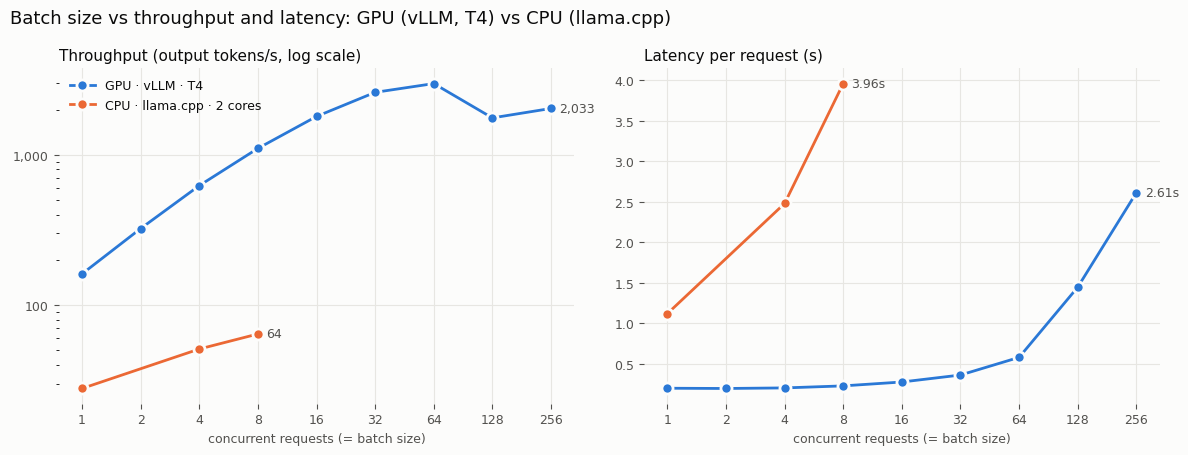

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

# CPU numbers measured in Step 5 (results/llamacpp_fp16_probe.txt): 4 vCPU, 2 threads, 32 tokens.
cpu = pd.DataFrame({"concurrency": [1, 4, 8], "tokens_per_s": [27.8, 50.9, 64.1],
                    "mean_latency_s": [1.12, 2.48, 3.96]})
gpu = sweep_df

BLUE, ORANGE = "#2a78d6", "#eb6834"                      # validated categorical slots 1-2
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), facecolor=SURFACE)
panels = [("tokens_per_s", "Throughput (output tokens/s, log scale)", True),
          ("mean_latency_s", "Latency per request (s)", False)]
for ax, (col, title, logy) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    for df, color, name in [(gpu, BLUE, "GPU · vLLM · T4"), (cpu, ORANGE, "CPU · llama.cpp · 2 cores")]:
        ax.plot(df["concurrency"], df[col], color=color, lw=2, marker="o", ms=8,
                markeredgecolor=SURFACE, markeredgewidth=2, label=name, zorder=3)
        last = df.iloc[-1]
        ax.annotate(f"{last[col]:,.0f}" if col == "tokens_per_s" else f"{last[col]:.2f}s",
                    (last["concurrency"], last[col]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK2)
    ax.set_xscale("log", base=2)
    ticks = sorted(set(gpu["concurrency"]) | set(cpu["concurrency"]))
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}"))
    ax.xaxis.set_minor_locator(NullLocator())
    if logy:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("concurrent requests (= batch size)", color=INK2, fontsize=9)
    ax.grid(True, color=GRID, lw=0.8, zorder=0)
    ax.tick_params(colors=INK2, labelsize=9)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(frameon=False, fontsize=9, labelcolor=INK)
fig.suptitle("Batch size vs throughput and latency: GPU (vLLM, T4) vs CPU (llama.cpp)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(f"results/batch_scaling_gpu_vs_cpu.png", dpi=150, facecolor=SURFACE)
plt.show()

## 7. Load test — same harness, same prompts, same settings as every other version

A fresh vLLM server for each user count, so one run's backlog can't pollute the next.
After each run we print vLLM's own counters (queue length, prefix-cache hits).

In [8]:
import re

def vllm_counters(path):
    keep = ("num_requests_running", "num_requests_waiting", "prefix_cache_queries",
            "prefix_cache_hits", "kv_cache_usage", "gpu_cache_usage", "num_preemptions")
    vals = {}
    for line in open(path):
        if line.startswith("#"):
            continue
        m = re.match(r"vllm:([a-z_]+)(?:\{[^}]*\})?\s+([0-9.eE+-]+)$", line.strip())
        if m and any(k in m.group(1) for k in keep):
            vals[m.group(1)] = vals.get(m.group(1), 0.0) + float(m.group(2))
    return vals

for users in USERS_LIST:
    start_vllm()
    sh(f"bash loadtest/run_load.sh {LABEL} {users} {LOAD_DURATION_S} http://localhost:{PORT}", check=False)
    mfile = f"results/raw/{LABEL}_u{users}_metrics.txt"
    if os.path.exists(mfile) and os.path.getsize(mfile):
        c = vllm_counters(mfile)
        hits, queries = c.get("prefix_cache_hits_total", 0), c.get("prefix_cache_queries_total", 0)
        print(f"vLLM counters @ {users} users: waiting={c.get('num_requests_waiting')} "
              f"running={c.get('num_requests_running')} preemptions={c.get('num_preemptions_total')} "
              f"prefix-cache hit rate={hits / queries:.0%}" if queries else f"vLLM counters: {c}")
    sh(f"cp {LOG} results/raw/{LABEL}_u{users}_server.log", check=False)
stop_vllm()

vLLM ready after 63s | attention backend setting: default (auto)
>>> vllm_t4_fp16_u10: 10 users for 180s -> http://localhost:8000 (spawn 10/s, timeout 60s, fd limit 65536)

=== vllm_t4_fp16 @ 10 users (steady-state window 150s, first 30s excluded)
requests 663 | ok 663 | error rate 0.0% 
latency (ok): p50 0.36s  p95 0.42s  p99 0.51s
throughput 4.4283 req/s | goodput (<= 15s) 4.4283 req/s | 216.58 tokens/s
locust CPU: 2% of one core
appended -> results/loadtest_summary.csv
/kaggle/working/llm-serving-at-scale/loadtest/summarize.py:117: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  new = pd.concat([pd.read_csv(args.out), new], ignore_index=True)
vLLM counters @ 10 users: waiting=0.0 running=0.0 preemptions=0.0 prefix-cache hit rate=74%
vLLM r

## 8. Compare with every version so far

In [9]:
_ = sh("python loadtest/show_summary.py version_a_guarded llamacpp vllm", check=False)

label  users  n_ok  error_rate  p50_s  p95_s  throughput_rps  goodput_rps  tokens_per_s  avg_batch  server_completed  client_ok_total  server_rejected  server_waiting_at_end
version_a_guarded     10    29      0.9463   8.09  12.39          0.1844       0.1844          8.19        NaN              36.0               36            619.0                    0.0
version_a_guarded    100    26      0.9964   9.52  12.76          0.1707       0.1707          7.77        NaN              33.0               33           8661.0                    0.0
version_a_guarded   1000    19      0.9997  12.84  16.28          0.1238       0.0912          6.46        NaN              24.0               24          85294.0                    0.0
llamacpp_fp16_np8     10   194      0.0000   6.52   9.30          1.2643       1.2643         61.79       6.85               NaN              232              NaN                    0.0
llamacpp_fp16_np8    100   199      0.2196  55.50  59.32          0.9706       0.0

## 9. Save the results → download `step6_results.zip` from the Output panel

In [10]:
import glob, zipfile
env = sh(f"nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv,noheader; "
         f"{sys.executable} -m pip show vllm torch 2>/dev/null | grep -E '^(Name|Version)'; nproc; free -h | head -2",
         check=False)
with open(f"results/{LABEL}_environment.txt", "w") as f:
    f.write(env + f"\nvLLM startup to healthy: {startup_s:.0f}s\n"
            f"attention backend setting: {os.environ.get('VLLM_ATTENTION_BACKEND', 'default (auto)')}\n")
sh(f"grep -iE 'KV cache|maximum concurrency|attention backend' {LOG} > results/{LABEL}_startup_facts.txt", check=False)

files = (["results/loadtest_summary.csv", "results/batch_scaling_gpu_vs_cpu.png"]
         + glob.glob(f"results/{LABEL}_*"))
zpath = f"{WORK}/step6_results.zip"
with zipfile.ZipFile(zpath, "w") as z:
    for p in files:
        if os.path.exists(p):
            z.write(p)
print(f"saved {zpath} with:", *files, sep="\n  ")

Tesla T4, 580.178.04, 15360 MiB
Tesla T4, 580.178.04, 15360 MiB
Name: vllm
Version: 0.18.1
Name: torch
Version: 2.10.0
4
               total        used        free      shared  buff/cache   available
Mem:            31Gi       1.6Gi       4.8Gi       1.7Mi        25Gi        29Gi
saved /kaggle/working/step6_results.zip with:
  results/loadtest_summary.csv
  results/batch_scaling_gpu_vs_cpu.png
  results/vllm_t4_fp16_startup_facts.txt
  results/vllm_t4_fp16_batch_sweep.csv
  results/vllm_t4_fp16_environment.txt
